# 04 - SVM trên Iris

Mục tiêu: phân loại ba loại hoa diên vĩ bằng SVM, so sánh các kernel `linear`, `poly`, `rbf`, `sigmoid` bằng cross-validation và đánh giá trên test set.

## 1. Load data và EDA ngắn

Shape: (150, 6)
Missing values: 0
Phân bố target:
target_name
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target,target_name
0,5.1,3.5,1.4,0.2,0,setosa
1,4.9,3.0,1.4,0.2,0,setosa
2,4.7,3.2,1.3,0.2,0,setosa
3,4.6,3.1,1.5,0.2,0,setosa
4,5.0,3.6,1.4,0.2,0,setosa


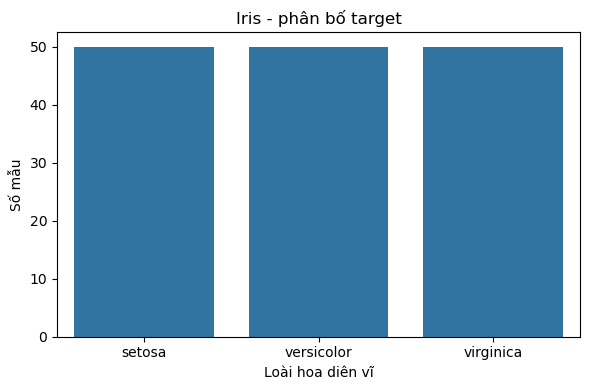

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

RANDOM_STATE = 101
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
FIGURES = ROOT / 'figures'
FIGURES.mkdir(exist_ok=True)

iris = load_iris(as_frame=True)
df = iris.frame.copy()
df['target_name'] = df['target'].map(dict(enumerate(iris.target_names)))
X = df[iris.feature_names]
y = df['target']
print('Shape:', df.shape)
print('Missing values:', int(df.isna().sum().sum()))
print('Phân bố target:')
print(df['target_name'].value_counts().sort_index())
display(df.head())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='target_name', order=iris.target_names)
plt.title('Iris - phân bố target')
plt.xlabel('Loài hoa diên vĩ')
plt.ylabel('Số mẫu')
plt.tight_layout()
plt.savefig(FIGURES / '04_iris_target_distribution.png', dpi=150)
plt.show()

## 2. Tiền xử lý và chia dữ liệu

In [2]:
# StandardScaler nằm trong Pipeline để chỉ fit trên từng fold train, tránh data leakage.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print('Train:', X_train.shape, '| Test:', X_test.shape)

pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(random_state=RANDOM_STATE))
])

Train: (120, 4) | Test: (30, 4)


## 3. Train và tuning kernel bằng cross-validation

Best params: {'svc__kernel': 'linear'}
Best CV accuracy: 0.975
  param_svc__kernel  mean_train_score  mean_test_score
0            linear          0.985417         0.975000
1              poly          0.920833         0.891667
2               rbf          0.981250         0.958333
3           sigmoid          0.906250         0.900000


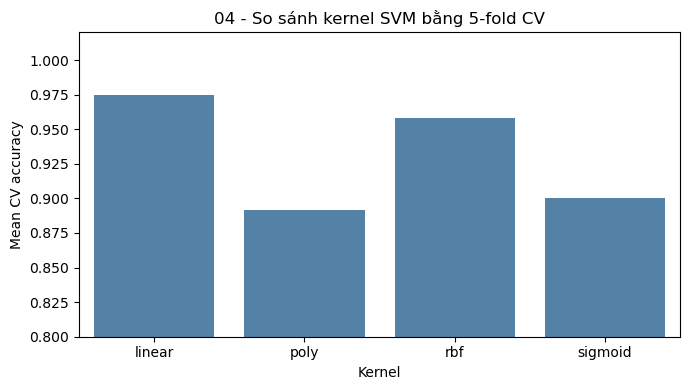

In [3]:
param_grid = {'svc__kernel': ['linear', 'poly', 'rbf', 'sigmoid']}
search = GridSearchCV(pipe, param_grid, scoring='accuracy', cv=5, return_train_score=True, n_jobs=-1)
search.fit(X_train, y_train)
print('Best params:', search.best_params_)
print('Best CV accuracy:', round(search.best_score_, 4))

cv_results = pd.DataFrame(search.cv_results_)
print(cv_results[['param_svc__kernel', 'mean_train_score', 'mean_test_score']])
plt.figure(figsize=(7, 4))
sns.barplot(data=cv_results, x='param_svc__kernel', y='mean_test_score', color='steelblue')
plt.ylim(0.8, 1.02)
plt.xlabel('Kernel')
plt.ylabel('Mean CV accuracy')
plt.title('04 - So sánh kernel SVM bằng 5-fold CV')
plt.tight_layout()
plt.savefig(FIGURES / '04_iris_kernel_cv.png', dpi=150)
plt.show()

## 4. đánh giá trên test set

accuracy     0.9667
precision    0.9697
recall       0.9667
f1           0.9666
dtype: float64
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



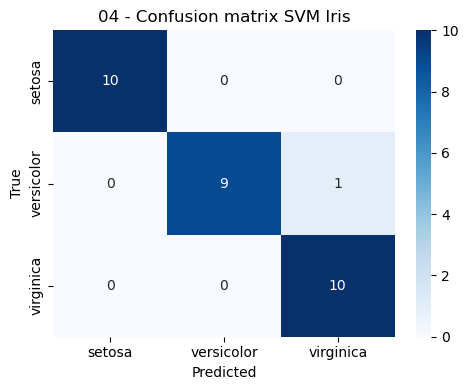

In [4]:
best_model = search.best_estimator_
y_pred = best_model.predict(X_test)
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred, average='weighted', zero_division=0),
    'recall': recall_score(y_test, y_pred, average='weighted', zero_division=0),
    'f1': f1_score(y_test, y_pred, average='weighted', zero_division=0),
}
print(pd.Series(metrics).round(4))
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=iris.target_names, yticklabels=iris.target_names)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('04 - Confusion matrix SVM Iris')
plt.tight_layout()
plt.savefig(FIGURES / '04_iris_svm_confusion_matrix.png', dpi=150)
plt.show()

## 5. Nhận xét và bảng kết quả tóm tắt

Iris có kích thước nhỏ và các lớp khá tách biệt nên SVM thường đạt kết quả rất cao. Kernel tốt nhất được chọn bằng CV trên train, không dùng test set; chênh lệch train/test được dùng để nhận xét overfitting.

In [5]:
best_row = cv_results.loc[cv_results['rank_test_score'].idxmin()]
print('Train CV accuracy:', round(float(best_row['mean_train_score']), 4))
print('Validation CV accuracy:', round(float(best_row['mean_test_score']), 4))

summary_path = FIGURES / 'results_summary.csv'
rows = []
if summary_path.exists():
    with summary_path.open(newline='', encoding='utf-8') as f:
        rows = [r for r in csv.DictReader(f) if r['notebook'] != '04_iris_svm']
fieldnames = ['notebook', 'dataset', 'model', 'best_params', 'accuracy', 'precision', 'recall', 'f1', 'roc_auc']
rows.append({
    'notebook': '04_iris_svm', 'dataset': 'iris', 'model': 'SVM',
    'best_params': repr(search.best_params_),
    'accuracy': metrics['accuracy'], 'precision': metrics['precision'],
    'recall': metrics['recall'], 'f1': metrics['f1'], 'roc_auc': ''
})
with summary_path.open('w', newline='', encoding='utf-8') as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(rows)
print('Đã cập nhật:', summary_path)

Train CV accuracy: 0.9854
Validation CV accuracy: 0.975
Đã cập nhật: D:\ML_Lab_Group_2026\Lab05_ModelTraining\Lab05\figures\results_summary.csv
